# Predicting the Austin Grand Prix finishing order

**Author:** Tanya Sasnouskaya · M.S. in Artificial Intelligence capstone, extended

Can qualifying data predict how a Formula 1 race at the Circuit of the Americas will finish?
This notebook tests the original capstone model honestly, against the simplest possible rule
(**"drivers finish where they start"**), and then improves it.

Every model is evaluated the way it would be used for real: to predict a given year's race,
it only sees data from **before** that race.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import GradientBoostingRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import build_dataset, COTA_CIRCUIT_ID, ORIGINAL_FEATURES, SIMPLE_FEATURES, FORM_FEATURES

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
BLUE, ORANGE, LIGHT = "#2a78d6", "#eb6834", "#9ec5f4"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "font.size": 10.5, "figure.dpi": 110,
})
pd.set_option("display.precision", 2)

df = build_dataset(start_year=2014)
austin = df[df["circuitId"] == COTA_CIRCUIT_ID]
print(f"Driver-race rows since 2014: {len(df):,} across {df['raceId'].nunique()} races")
print(f"Austin races in the data: {sorted(austin['year'].unique())}")

Driver-race rows since 2014: 4,626 across 228 races
Austin races in the data: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


## 1. Who wins in Austin

In [2]:
winners = austin[austin["positionOrder"] == 1][["year", "driver", "team", "grid"]]
winners = winners.rename(columns={"grid": "started"}).reset_index(drop=True)
winners

,year,driver,team,started
0,2014,Lewis Hamilton,Mercedes,2
1,2015,Lewis Hamilton,Mercedes,2
2,2016,Lewis Hamilton,Mercedes,1
3,2017,Lewis Hamilton,Mercedes,1
4,2018,Kimi Räikkönen,Ferrari,2
5,2019,Valtteri Bottas,Mercedes,1
6,2021,Max Verstappen,Red Bull,1
7,2022,Max Verstappen,Red Bull,2
8,2023,Max Verstappen,Red Bull,6
9,2024,Charles Leclerc,Ferrari,4


Pole position is no guarantee here: the 2023 and 2024 winners started 6th and 4th, which is
exactly why a model that only copies the grid has room to be beaten.

## 2. The test

Four ways to predict the finishing order of each Austin race from 2018 to 2024 (there was no race in 2020):

| Approach | What it uses | Trained on |
|---|---|---|
| **Grid baseline** | Finishing position = starting position | nothing |
| **Original capstone model** | Best qualifying lap, gap to pole, qualifying sessions reached, grid | previous Austin races only |
| **All-races model** | Gap to pole (%), qualifying sessions reached, grid | every race since 2014 before that date |
| **All-races + form** | The above plus each driver's average finish and each team's points over their last 5 races | every race since 2014 before that date |

All models are gradient-boosted trees (`GradientBoostingRegressor`), the algorithm used in the original capstone.

Scores: **MAE** = average number of places a prediction is off by (lower is better); **winner** = did the
predicted winner win; **podium** = how many of the actual top three were in the predicted top three.

In [3]:
def score(test, pred, model, year):
    ranked = test.assign(pred=pred).sort_values("pred")
    actual_top3 = set(test.nsmallest(3, "positionOrder")["driverId"])
    return {
        "year": year, "model": model,
        "mae": np.mean(np.abs(pred - test["positionOrder"])),
        "winner_correct": int(ranked.iloc[0]["positionOrder"] == 1),
        "podium_hits": len(set(ranked.head(3)["driverId"]) & actual_top3),
        "predicted_winner": ranked.iloc[0]["driver"],
    }

def fit_predict(train, test, feats):
    model = GradientBoostingRegressor(random_state=42).fit(train[feats], train["positionOrder"])
    return model.predict(test[feats])

TEST_YEARS = [2018, 2019, 2021, 2022, 2023, 2024]
rows, preds_2024, podiums = [], {}, []
for year in TEST_YEARS:
    test = austin[austin["year"] == year]
    before = df[df["date"] < test["date"].min()]
    p = {
        "Grid baseline": test["grid"].to_numpy(dtype=float),
        "Original capstone model": fit_predict(austin[austin["year"] < year], test, ORIGINAL_FEATURES),
        "All-races model": fit_predict(before, test, SIMPLE_FEATURES),
        "All-races + form": fit_predict(before, test, FORM_FEATURES),
    }
    for name, pred in p.items():
        rows.append(score(test, pred, name, year))
    predicted = test.assign(pred=p["All-races + form"]).sort_values("pred")
    actual = test.sort_values("positionOrder")
    podiums.append({"year": year,
                    "predicted_top_3": ", ".join(predicted["surname"].head(3)),
                    "actual_top_3": ", ".join(actual["surname"].head(3)),
                    "podium_drivers_correct": f"{len(set(predicted['driverId'].head(3)) & set(actual['driverId'].head(3)))} / 3"})
    if year == 2024:
        preds_2024 = p

results = pd.DataFrame(rows)
order = ["Grid baseline", "Original capstone model", "All-races model", "All-races + form"]
summary = (results.groupby("model")
           .agg(avg_places_off=("mae", "mean"), winners_correct=("winner_correct", "sum"),
                podium_hits=("podium_hits", "sum"))
           .loc[order])
summary["winners_correct"] = summary["winners_correct"].astype(str) + " / 6"
summary["podium_hits"] = summary["podium_hits"].astype(str) + " / 18"
summary

,avg_places_off,winners_correct,podium_hits
model,,,
Grid baseline,4.35,2 / 6,12 / 18
Original capstone model,4.15,3 / 6,9 / 18
All-races model,3.74,2 / 6,12 / 18
All-races + form,3.65,2 / 6,11 / 18


In [4]:
results.pivot(index="year", columns="model", values="mae")[order].round(2)

model,Grid baseline,Original capstone model,All-races model,All-races + form
year,,,,
2018,5.7,4.01,4.40,4.26
2019,3.1,5.10,3.19,3.15
2021,2.4,3.50,2.44,2.25
2022,5.4,3.65,4.18,4.10
2023,5.7,4.52,4.73,4.85
2024,3.8,4.10,3.47,3.29


### The predictions themselves

Predicted podium from the **All-races + form** model for each race, next to what actually happened.

In [5]:
pd.DataFrame(podiums)

,year,predicted_top_3,actual_top_3,podium_drivers_correct
0,2018,"Hamilton, Räikkönen, Bottas","Räikkönen, Verstappen, Hamilton",2 / 3
1,2019,"Bottas, Vettel, Verstappen","Bottas, Hamilton, Verstappen",2 / 3
2,2021,"Verstappen, Hamilton, Pérez","Verstappen, Hamilton, Pérez",3 / 3
3,2022,"Sainz, Pérez, Verstappen","Verstappen, Hamilton, Leclerc",1 / 3
4,2023,"Norris, Leclerc, Hamilton","Verstappen, Norris, Sainz",1 / 3
5,2024,"Norris, Verstappen, Sainz","Leclerc, Sainz, Verstappen",2 / 3


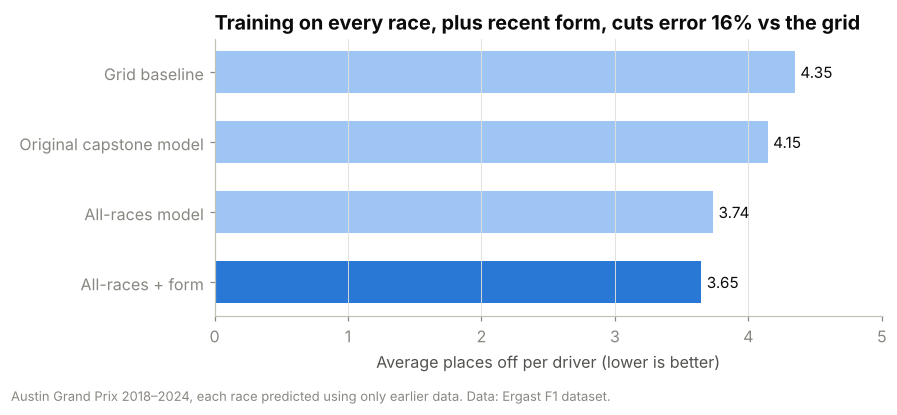

In [6]:
mae = results.groupby("model")["mae"].mean().loc[order]
fig, ax = plt.subplots(figsize=(8.2, 3.6))
colors = [LIGHT, LIGHT, LIGHT, BLUE]
ax.barh(order[::-1], mae[::-1], color=colors[::-1], height=0.6)
for y, v in enumerate(mae[::-1]):
    ax.text(v + 0.04, y, f"{v:.2f}", va="center", color=INK, fontsize=10)
ax.set_xlim(0, 5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Average places off per driver (lower is better)")
improvement = (1 - mae.iloc[-1] / mae.iloc[0]) * 100
ax.set_title(f"Training on every race, plus recent form, cuts error {improvement:.0f}% vs the grid")
fig.text(0.01, -0.03, "Austin Grand Prix 2018–2024, each race predicted using only earlier data. "
         "Data: Ergast F1 dataset.", color=MUTED, fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG / "1_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

**Finding.** "Drivers finish where they start" is a strong baseline: it is off by about 4.3 places
per driver. The original capstone model beats it slightly and picks more winners, but six earlier
Austin races are very little to learn from. Training on **every race since 2014** gives the model
thousands of examples instead of about a hundred, and adding **recent driver and team form** captures
who is quick right now, which the grid alone misses.

## 3. Case study: the 2024 race

Charles Leclerc won from 4th on the grid, ahead of Carlos Sainz and Max Verstappen.

In [7]:
test24 = austin[austin["year"] == 2024].copy()
for name in ["All-races + form", "Grid baseline"]:
    test24[name] = preds_2024[name]
show = test24.sort_values("All-races + form").head(8)
show = show.assign(
    predicted_rank=range(1, len(show) + 1),
    grid=show["grid"].astype(int),
    actual_finish=show["positionOrder"],
)[["predicted_rank", "driver", "team", "grid", "actual_finish"]].reset_index(drop=True)
show

,predicted_rank,driver,team,grid,actual_finish
0,1,Lando Norris,McLaren,1,4
1,2,Max Verstappen,Red Bull,2,3
2,3,Carlos Sainz,Ferrari,3,2
3,4,Oscar Piastri,McLaren,5,5
4,5,Charles Leclerc,Ferrari,4,1
5,6,Sergio Pérez,Red Bull,9,7
6,7,Fernando Alonso,Aston Martin,7,13
7,8,Pierre Gasly,Alpine F1 Team,6,12


## 4. Does it hold beyond Austin?

Six races is a small test, so the same comparison is repeated on **every race of the 2022–2024 seasons**.

In [8]:
rows = []
for race_id, test in df[df["year"].between(2022, 2024)].groupby("raceId"):
    before = df[df["date"] < test["date"].min()]
    for name, feats in [("Grid baseline", None), ("All-races model", SIMPLE_FEATURES), ("All-races + form", FORM_FEATURES)]:
        pred = test["grid"].to_numpy(dtype=float) if feats is None else fit_predict(before, test, feats)
        rows.append({"model": name, "mae": np.mean(np.abs(pred - test["positionOrder"])),
                     "winner_correct": int(test["positionOrder"].to_numpy()[np.argmin(pred)] == 1)})
season = pd.DataFrame(rows)
print(f"Races tested: {season.shape[0] // 3}")
season.groupby("model").agg(avg_places_off=("mae", "mean"), winner_hit_rate=("winner_correct", "mean")).loc[
    ["Grid baseline", "All-races model", "All-races + form"]]

Races tested: 68


,avg_places_off,winner_hit_rate
model,,
Grid baseline,3.51,0.51
All-races model,3.40,0.46
All-races + form,3.20,0.56


**Finding.** Across 68 races the form-aware model is again the most accurate and picks the winner
more often than "pole wins", so the improvement is not an Austin fluke.

## 5. What the model relies on

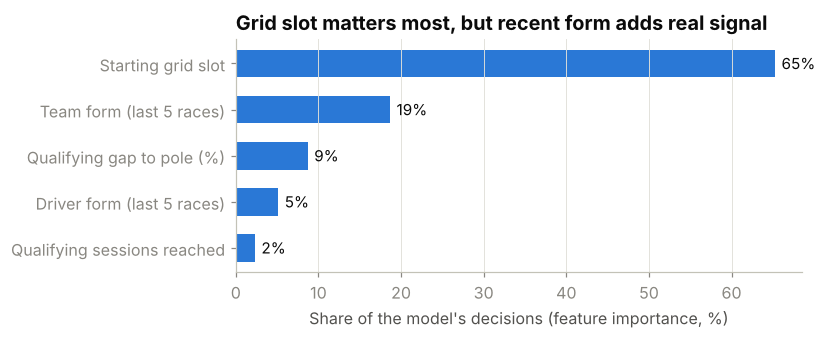

In [9]:
final = GradientBoostingRegressor(random_state=42).fit(df[FORM_FEATURES], df["positionOrder"])
labels = {"grid": "Starting grid slot", "pct_off_pole": "Qualifying gap to pole (%)",
          "q_sessions": "Qualifying sessions reached", "driver_form": "Driver form (last 5 races)",
          "team_form": "Team form (last 5 races)"}
imp = pd.Series(final.feature_importances_, index=[labels[f] for f in FORM_FEATURES]).sort_values()
fig, ax = plt.subplots(figsize=(7.6, 3.2))
ax.barh(imp.index, imp.values * 100, color=BLUE, height=0.6)
for y, v in enumerate(imp.values * 100):
    ax.text(v + 0.8, y, f"{v:.0f}%", va="center", color=INK, fontsize=10)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of the model's decisions (feature importance, %)")
ax.set_title("Grid slot matters most, but recent form adds real signal")
fig.tight_layout()
fig.savefig(FIG / "2_feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()

## Limitations and next steps

- Races include crashes, mechanical failures and safety cars that no pre-race model can foresee;
  those account for much of the remaining error.
- The Ergast dataset ends with the 2024 season. The live pipeline in `fastf1_pipeline/` pulls fresh
  qualifying data from FastF1 on race weekend (`predict_2025.py`).
- Natural extensions: tyre strategy and long-run pace from practice sessions, weather, and a ranking
  model (learning-to-rank) instead of regression on positions.